In [7]:
# 告诉 Jupyter 把 matplotlib 图表直接显示在 notebook 里，而不是弹新窗口
%matplotlib inline

# 导入数值计算库（数组、随机数）
import numpy as np
# 导入数据处理库（表格、CSV 读写、统计分析）
import pandas as pd
# 导入绘图库（画图）
import matplotlib.pyplot as plt
# 从 IPython 导入 display 函数，用于强制显示图表对象
from IPython.display import display

# 固定随机数种子为 42，保证每次跑出来的结果一模一样（可复现）
np.random.seed(42)

# ========== 模拟 LFP（磷酸铁锂）循环数据 ==========

# 定义循环总圈数：模拟 200 圈充放电
n_cycles = 200

# 生成 1~200 的循环编号数组，方便后面画 x 轴
cycles = np.arange(1, n_cycles + 1)

# 模拟每圈放电容量（mAh/g）：
# 160 是初始容量，后面两项是衰减项（线性 + 幂律），最后加高斯噪声模拟实验误差
capacity_mAh_g = 160 * (1 - 0.0015 * cycles - 0.000008 * cycles**1.6) + np.random.normal(0, 0.8, n_cycles)

# 模拟库仑效率（%）：
# 随循环略微上升（SEI 稳定），加噪声，最后裁剪到 99.0~99.99 的合理范围
coulomb_eff = 99.5 + 0.002 * cycles + np.random.normal(0, 0.05, n_cycles)
coulomb_eff = np.clip(coulomb_eff, 99.0, 99.99)

# 把上面三个数组组装成 pandas DataFrame（表格）
df = pd.DataFrame({
    'cycle': cycles,                      # 第几圈
    'capacity_mAh_g': capacity_mAh_g,     # 该圈放电容量
    'coulomb_eff': coulomb_eff,           # 该圈库仑效率
    'retention_pct': capacity_mAh_g / capacity_mAh_g[0] * 100  # 容量保持率（相对第 1 圈的百分比）
})

# 把 DataFrame 存成 CSV 文件，方便以后直接用 Excel 或别的工具打开
df.to_csv('lpf_cycling_simulated.csv', index=False)

# 打印初始和最终容量，快速确认数据生成是否正常
print(f"Data saved. Cycle 1: {capacity_mAh_g[0]:.1f} mAh/g | Cycle 200: {capacity_mAh_g[-1]:.1f} mAh/g")

Data saved. Cycle 1: 160.2 mAh/g | Cycle 200: 104.9 mAh/g


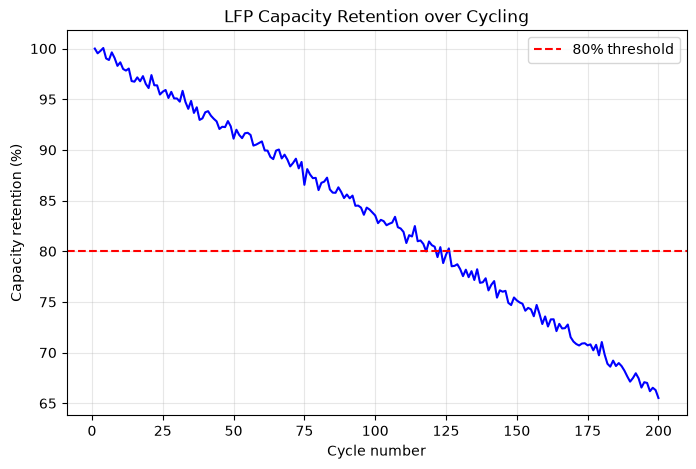

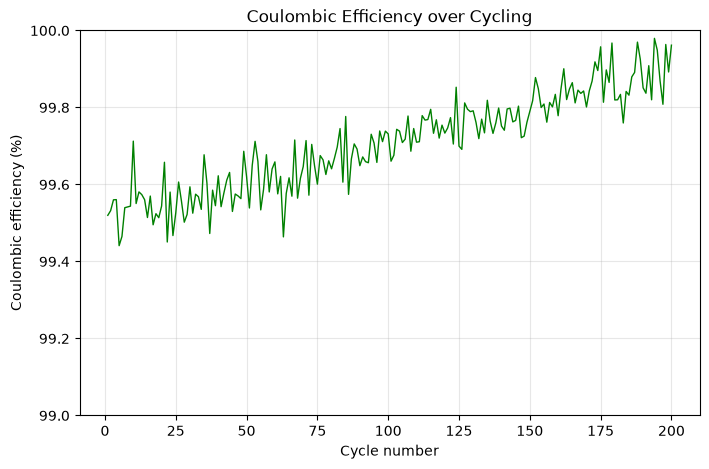

In [2]:
# ========== 图1：容量保持率 ==========
# 新建一个 8x5 英寸的画布
plt.figure(figsize=(8, 5))
# 画容量保持率随循环圈数的变化曲线，蓝色实线，线宽 1.5
plt.plot(df['cycle'], df['retention_pct'], 'b-', linewidth=1.5)
# 画一条红色虚线标记 80% 容量保持率（行业常用的寿命终点标准）
plt.axhline(y=80, color='r', linestyle='--', label='80% threshold')
# x 轴标签
plt.xlabel('Cycle number')
# y 轴标签
plt.ylabel('Capacity retention (%)')
# 图标题
plt.title('LFP Capacity Retention over Cycling')
# 显示图例
plt.legend()
# 显示网格线（透明度 0.3，浅色不抢主体）
plt.grid(True, alpha=0.3)
# 渲染并显示这张图
plt.show()

# ========== 图2：库仑效率 ==========
# 新建第二个画布
plt.figure(figsize=(8, 5))
# 画库仑效率随循环圈数的变化曲线，绿色实线
plt.plot(df['cycle'], df['coulomb_eff'], 'g-', linewidth=1)
# x 轴标签
plt.xlabel('Cycle number')
# y 轴标签
plt.ylabel('Coulombic efficiency (%)')
# 图标题
plt.title('Coulombic Efficiency over Cycling')
# 限制 y 轴范围，让细节看得更清楚
plt.ylim(99.0, 100.0)
# 显示网格线
plt.grid(True, alpha=0.3)
# 渲染并显示
plt.show()

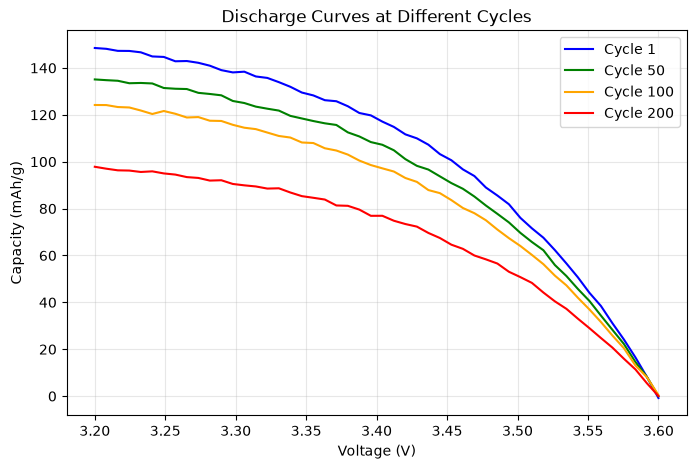

In [8]:
# ========== 定义放电曲线函数 ==========
def discharge_curve(cycle_num, capacity):
    """根据循环圈数和当前容量，模拟一条放电曲线（电压 vs 容量）"""
    # 生成 50 个从 3.6V 到 3.2V 的等间距电压点
    v = np.linspace(3.6, 3.2, 50)
    # 用指数衰减模拟放电容量随电压的变化，加噪声模拟实验波动
    q = capacity * (1 - np.exp(-(3.6 - v) / 0.15)) + np.random.normal(0, 0.5, 50)
    # 返回电压数组和对应的容量数组
    return v, q

# ========== 图3：不同循环圈数的放电曲线对比 ==========
# 新建画布
plt.figure(figsize=(8, 5))

# 定义要对比的 4 个循环圈数和对应的颜色
colors = ['b', 'g', 'orange', 'r']
labels = [1, 50, 100, 200]

# 循环画 4 条曲线
for c, col in zip(labels, colors):
    # 调用函数生成第 c 圈的放电曲线
    v, q = discharge_curve(c, df.loc[c-1, 'capacity_mAh_g'])
    # 画这条曲线，用对应颜色，线宽 1.5，标签写循环圈数
    plt.plot(v, q, color=col, linewidth=1.5, label=f'Cycle {c}')

# x 轴标签
plt.xlabel('Voltage (V)')
# y 轴标签
plt.ylabel('Capacity (mAh/g)')
# 图标题
plt.title('Discharge Curves at Different Cycles')
# 显示图例（区分 4 条曲线）
plt.legend()
# 显示网格线
plt.grid(True, alpha=0.3)
# 渲染并显示
plt.show()

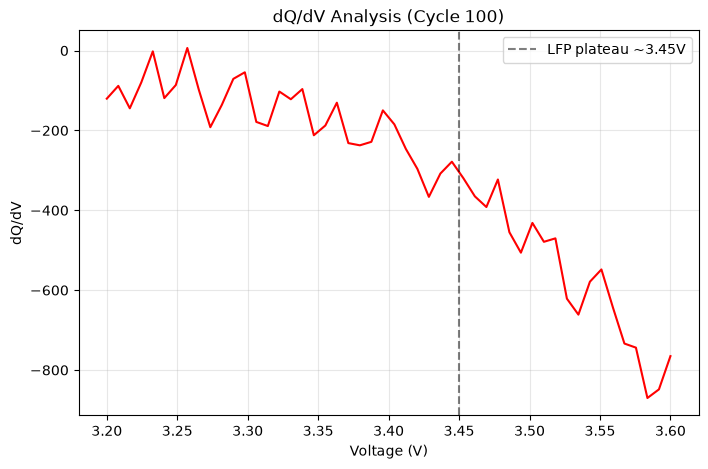

In [9]:
# ========== 图4：dQ/dV 微分容量分析 ==========
# 新建画布
plt.figure(figsize=(8, 5))

# 生成第 100 圈的放电曲线（电压和容量）
v100, q100 = discharge_curve(100, df.loc[99, 'capacity_mAh_g'])

# 对容量关于电压求导，得到 dQ/dV（微分容量）
# np.gradient 是数值微分：dQ/dV ≈ ΔQ / ΔV
dq_dv = np.gradient(q100, v100)

# 画 dQ/dV 曲线，红色实线
plt.plot(v100, dq_dv, 'r-', linewidth=1.5)

# 画一条黑色虚线标记 LFP 的特征电压平台 ~3.45V
# dQ/dV 在这个电压出现峰 = 对应相变反应
plt.axvline(x=3.45, color='k', linestyle='--', alpha=0.5, label='LFP plateau ~3.45V')

# x 轴标签
plt.xlabel('Voltage (V)')
# y 轴标签
plt.ylabel('dQ/dV')
# 图标题
plt.title('dQ/dV Analysis (Cycle 100)')
# 显示图例
plt.legend()
# 显示网格线
plt.grid(True, alpha=0.3)
# 渲染并显示
plt.show()

In [10]:
# ============================================================
# Cell 5: 集中导出所有产物
# Week 1: LFP 循环数据模拟与可视化
# 职责：建目录、保存图片、导出 JSON、写 README（唯一 IO 出口）
# ============================================================

import os
import json

# ---- 1. 创建输出目录 ----
export_dir = "week1_output"
os.makedirs(export_dir, exist_ok=True)

# ---- 2. 放电曲线函数（复用 Cell 3 定义）----
def discharge_curve(cycle_num, capacity):
    """根据循环圈数和当前容量，模拟一条放电曲线（电压 vs 容量）"""
    v = np.linspace(3.6, 3.2, 50)
    q = capacity * (1 - np.exp(-(3.6 - v) / 0.15)) + np.random.normal(0, 0.5, 50)
    return v, q

# ---- 3. 重新画图并保存 ----

# 图1：容量保持率（Cell 2）
fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(df['cycle'], df['retention_pct'], 'b-', linewidth=1.5)
ax1.axhline(y=80, color='r', linestyle='--', label='80% threshold')
ax1.set_xlabel('Cycle number')
ax1.set_ylabel('Capacity retention (%)')
ax1.set_title('LFP Capacity Retention over Cycling')
ax1.legend()
ax1.grid(True, alpha=0.3)
fig1.tight_layout()
fig1.savefig(os.path.join(export_dir, 'capacity_retention.png'),
             dpi=150, bbox_inches='tight')
plt.close(fig1)

# 图2：库仑效率（Cell 2）
fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.plot(df['cycle'], df['coulomb_eff'], 'g-', linewidth=1)
ax2.set_xlabel('Cycle number')
ax2.set_ylabel('Coulombic efficiency (%)')
ax2.set_title('Coulombic Efficiency over Cycling')
ax2.set_ylim(99.0, 100.0)
ax2.grid(True, alpha=0.3)
fig2.tight_layout()
fig2.savefig(os.path.join(export_dir, 'coulomb_efficiency.png'),
             dpi=150, bbox_inches='tight')
plt.close(fig2)

# 图3：不同循环圈数放电曲线对比（Cell 3）
fig3, ax3 = plt.subplots(figsize=(8, 5))
colors_3 = ['b', 'g', 'orange', 'r']
labels_3 = [1, 50, 100, 200]
for c, col in zip(labels_3, colors_3):
    v, q = discharge_curve(c, df.loc[c-1, 'capacity_mAh_g'])
    ax3.plot(v, q, color=col, linewidth=1.5, label=f'Cycle {c}')
ax3.set_xlabel('Voltage (V)')
ax3.set_ylabel('Capacity (mAh/g)')
ax3.set_title('Discharge Curves at Different Cycles')
ax3.legend()
ax3.grid(True, alpha=0.3)
fig3.tight_layout()
fig3.savefig(os.path.join(export_dir, 'discharge_curves.png'),
             dpi=150, bbox_inches='tight')
plt.close(fig3)

# 图4：dQ/dV 微分容量分析（Cell 4）
fig4, ax4 = plt.subplots(figsize=(8, 5))
v100, q100 = discharge_curve(100, df.loc[99, 'capacity_mAh_g'])
dq_dv = np.gradient(q100, v100)
ax4.plot(v100, dq_dv, 'r-', linewidth=1.5)
ax4.axvline(x=3.45, color='k', linestyle='--', alpha=0.5, label='LFP plateau ~3.45V')
ax4.set_xlabel('Voltage (V)')
ax4.set_ylabel('dQ/dV')
ax4.set_title('dQ/dV Analysis (Cycle 100)')
ax4.legend()
ax4.grid(True, alpha=0.3)
fig4.tight_layout()
fig4.savefig(os.path.join(export_dir, 'dq_dv_analysis.png'),
             dpi=150, bbox_inches='tight')
plt.close(fig4)

print(f"  Saved -> {export_dir}/capacity_retention.png")
print(f"  Saved -> {export_dir}/coulomb_efficiency.png")
print(f"  Saved -> {export_dir}/discharge_curves.png")
print(f"  Saved -> {export_dir}/dq_dv_analysis.png")

# ---- 4. 计算关键统计量 ----

cap_initial = float(df['capacity_mAh_g'].iloc[0])
cap_final = float(df['capacity_mAh_g'].iloc[-1])
cap_fade_total = cap_initial - cap_final
cap_fade_per_cycle = cap_fade_total / (n_cycles - 1)

retention_final = float(df['retention_pct'].iloc[-1])

ce_mean = float(df['coulomb_eff'].mean())
ce_std = float(df['coulomb_eff'].std())
ce_min = float(df['coulomb_eff'].min())

# 失效圈数（容量保持率首次跌破 80%）
eol_mask = df['retention_pct'] < 80.0
eol_cycle = int(df['cycle'][eol_mask].iloc[0]) if eol_mask.any() else None

# 放电曲线统计：Cycle 1 vs Cycle 200 容量差
cap_c1 = float(df.loc[0, 'capacity_mAh_g'])
cap_c200 = float(df.loc[199, 'capacity_mAh_g'])
discharge_fade = cap_c1 - cap_c200

# dQ/dV 统计：Cycle 100 峰值位置和幅度
dqdv_max = float(np.max(dq_dv))
dqdv_peak_idx = int(np.argmax(dq_dv))
dqdv_peak_v = float(v100[dqdv_peak_idx])

print(f"\nStatistics:")
print(f"  Initial capacity: {cap_initial:.1f} mAh/g")
print(f"  Final capacity:   {cap_final:.1f} mAh/g")
print(f"  Total fade:       {cap_fade_total:.1f} mAh/g ({cap_fade_per_cycle:.3f} mAh/g/cycle)")
print(f"  Retention (end):  {retention_final:.1f}%")
print(f"  CE mean:          {ce_mean:.3f} +/- {ce_std:.3f}%")
print(f"  CE min:           {ce_min:.3f}%")
if eol_cycle:
    print(f"  EOL (80%%):        Cycle {eol_cycle}")
else:
    print(f"  EOL (80%%):        Not reached within {n_cycles} cycles")
print(f"  Discharge fade (C1 vs C200): {discharge_fade:.1f} mAh/g")
print(f"  dQ/dV peak (C100): {dqdv_max:.1f} at {dqdv_peak_v:.2f}V")

# ---- 5. 导出 JSON ----

export_data = {
    "parameters": {
        "n_cycles": n_cycles,
        "initial_capacity_mAh_g": cap_initial,
        "capacity_fade_model": "linear + power_law (1.5e-3 * n + 8e-6 * n^1.6)",
        "noise_std": 0.8,
        "random_seed": 42,
        "discharge_curve_voltage_range": [3.6, 3.2],
        "discharge_curve_points": 50,
    },
    "statistics": {
        "final_capacity_mAh_g": round(cap_final, 2),
        "total_fade_mAh_g": round(cap_fade_total, 2),
        "fade_per_cycle_mAh_g": round(cap_fade_per_cycle, 4),
        "final_retention_pct": round(retention_final, 2),
        "coulomb_eff_mean_pct": round(ce_mean, 3),
        "coulomb_eff_std_pct": round(ce_std, 3),
        "coulomb_eff_min_pct": round(ce_min, 3),
        "eol_cycle_80pct": eol_cycle,
        "discharge_fade_c1_vs_c200_mAh_g": round(discharge_fade, 2),
        "dqdv_peak_magnitude": round(dqdv_max, 1),
        "dqdv_peak_voltage_V": round(dqdv_peak_v, 2),
    },
    "figures": {
        "capacity_retention": "capacity_retention.png",
        "coulomb_efficiency": "coulomb_efficiency.png",
        "discharge_curves": "discharge_curves.png",
        "dq_dv_analysis": "dq_dv_analysis.png",
    },
}

json_path = os.path.join(export_dir, 'week1_results.json')
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(export_data, f, indent=2, ensure_ascii=False)
print(f"\n  Saved -> {json_path}")

# ---- 6. 写 README ----

readme = f"""# Week 1: LFP Cycling Data Simulation & Visualization

## Model
- Simulated LFP (LiFePO4) full-cell cycling data, 200 cycles
- Capacity fade: linear + power-law decay + Gaussian noise (sigma=0.8 mAh/g)
- Coulombic efficiency: slight upward trend (SEI stabilization) + noise (sigma=0.05%)
- Discharge curves: exponential decay model V vs Q, 4 representative cycles (1/50/100/200)
- dQ/dV analysis: numerical differentiation of discharge curve (Cycle 100), LFP plateau at ~3.45V

## Parameters
- n_cycles = {n_cycles}
- Initial capacity = {cap_initial:.1f} mAh/g
- Fade: 0.15%/cycle (linear) + 0.0008*n^1.6 (power-law)
- CE noise sigma = 0.05%, capacity noise sigma = 0.8 mAh/g
- Random seed = 42 (reproducible)

## Results
- Final capacity: {cap_final:.1f} mAh/g
- Total fade: {cap_fade_total:.1f} mAh/g ({cap_fade_per_cycle:.3f} mAh/g/cycle)
- Final retention: {retention_final:.1f}%
- CE mean: {ce_mean:.3f} +/- {ce_std:.3f}%
- CE min: {ce_min:.3f}%
- EOL (80%): {'Cycle ' + str(eol_cycle) if eol_cycle else f'Not reached within {n_cycles} cycles'}
- Discharge fade (C1 vs C200): {discharge_fade:.1f} mAh/g
- dQ/dV peak (C100): {dqdv_max:.1f} at {dqdv_peak_v:.2f}V

## Files
- capacity_retention.png (capacity retention vs cycle, 80% threshold)
- coulomb_efficiency.png (coulombic efficiency vs cycle)
- discharge_curves.png (discharge curves at cycles 1/50/100/200)
- dq_dv_analysis.png (dQ/dV differential capacity, Cycle 100, LFP plateau marker)
- week1_results.json (parameters + statistics)
- lpf_cycling_simulated.csv (raw data, generated by Cell 1)

## Notebook Usage

### Cell Responsibility & Execution Order

| Cell | Responsibility | IO | Usage |
|---|---|---|---|
| Cell 1 | Import libs, generate simulated LFP cycling data | No (CSV only) | Must run first. Defines df, cycles, n_cycles. Edit fade params here. |
| Cell 2 | Plot capacity retention + coulombic efficiency | No | Depends on Cell 1 df. Run to preview figures. |
| Cell 3 | Discharge curve function + multi-cycle comparison | No | Depends on Cell 1 df. Defines discharge_curve() used by Cell 4. |
| Cell 4 | dQ/dV differential capacity analysis (Cycle 100) | No | Depends on Cell 3 discharge_curve(). Run to preview. |
| Cell 5 | Export: mkdir, save figs, JSON, README | **Yes (sole IO)** | Must run last. Re-runs overwrite outputs. |

### Minimum Execution Flow
### Partial Re-run Scenarios

| Scenario | Actions |
|---|--- |
| Change fade model params | Re-run Cell 1 -> Cell 2/3/4 -> Cell 5 |
| Change discharge curve model | Edit Cell 3 function, re-run Cell 3/4 -> Cell 5 |
| Change plot style | Edit Cell 2/3/4 or Cell 5 fig section, re-run Cell 5 |

Generated: 2026-10-10
"""

readme_path = os.path.join(export_dir, 'README.md')
with open(readme_path, 'w', encoding='utf-8') as f:
    f.write(readme)
print(f"  Saved -> {readme_path}")

# ---- 7. 完成提示 ----

print(f"\n{'='*60}")
print(f"Week 1 COMPLETE. All outputs in ./{export_dir}/")
print(f"{'='*60}")
print(f"\nDirectory contents:")
for f_name in sorted(os.listdir(export_dir)):
    f_path = os.path.join(export_dir, f_name)
    f_size = os.path.getsize(f_path)
    print(f"  {f_name:40s} ({f_size/1024:.1f} KB)")

  Saved -> week1_output/capacity_retention.png
  Saved -> week1_output/coulomb_efficiency.png
  Saved -> week1_output/discharge_curves.png
  Saved -> week1_output/dq_dv_analysis.png

Statistics:
  Initial capacity: 160.2 mAh/g
  Final capacity:   104.9 mAh/g
  Total fade:       55.2 mAh/g (0.277 mAh/g/cycle)
  Retention (end):  65.5%
  CE mean:          99.705 +/- 0.125%
  CE min:           99.441%
  EOL (80%%):        Cycle 118
  Discharge fade (C1 vs C200): 55.2 mAh/g
  dQ/dV peak (C100): 60.2 at 3.20V

  Saved -> week1_output\week1_results.json
  Saved -> week1_output\README.md

Week 1 COMPLETE. All outputs in ./week1_output/

Directory contents:
  README.md                                (2.4 KB)
  capacity_retention.png                   (58.5 KB)
  coulomb_efficiency.png                   (70.0 KB)
  discharge_curves.png                     (92.1 KB)
  dq_dv_analysis.png                       (55.0 KB)
  week1_results.json                       (0.9 KB)
